# 实验一：新闻文本分类

这次实验没有先指定某个模型作为答案，而是从四种分类器出发，逐步尝试文本表示、标题结构和 MLP 容量。主要想回答三个问题：模型选择带来多大差异；BoW、TF-IDF 和平均 Word2Vec 哪一种更合适；标题单独建模是否真的有帮助。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from summarize import load_results, tables

ROOT = Path.cwd()
config = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
records, runs = load_results()
result = tables()
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.precision', 4)

## 1. 先检查数据和划分

训练数据共有 7,368 条，标签分布比较均衡。主划分使用种子 66，按类别分层取 20% 作为验证集；种子 88 只复核已经选出的配置。词表、IDF 和 Word2Vec 都在训练部分拟合，测试集不参与调参。

邮件头中的作者、组织和主机字段被去掉，标题和正文保留。正文里的引用和签名没有继续清洗，因此这里不能把预处理称为完全去噪。

In [2]:
audit = json.loads((ROOT / 'results/data_audit.json').read_text(encoding='utf-8'))
split = json.loads((ROOT / 'results/split_summary.json').read_text(encoding='utf-8'))['seed_66']
display(pd.Series(audit['class_counts'], name='样本数').to_frame().T)
print('训练条数：', split['train_rows'])
print('验证条数：', split['validation_rows'])
print('因内容重复而不计分的验证行：', split['excluded_validation_rows'])
print('实际计分条数：', split['evaluated_validation_rows'])
assert split['train_rows'] + split['validation_rows'] == audit['samples']

,0,1,2,3,4,5,6,7,8,9
样本数,730,739,737,742,747,745,743,738,742,705


训练条数： 5894
验证条数： 1474
因内容重复而不计分的验证行： [2009, 6225]
实际计分条数： 1472


清洗后发现少量验证文本与训练文本完全相同。这些预测仍保存在结果文件中，但不计入模型选择分数；`raw_macro_f1` 保留排除前的结果。这样处理只排除了确定的完全重复，近重复帖子仍可能存在。

## 2. 文本表示和模型原理

BoW 记录词频，TF-IDF 在词频基础上降低跨文档常见词的权重。两者使用相同的一元词表和 L2 归一化，便于观察 IDF 本身的作用。平均 Word2Vec 把已登录词向量取均值，得到 200 维稠密表示；它会压缩词项信息，也不保留词序。

四种分类器的出发点不同：NB 根据条件独立假设累积词项证据；线性 SVM 寻找最大间隔超平面；LR 用交叉熵学习类别概率；MLP 通过 ReLU 隐层组合非线性特征。文本向量高维且稀疏，因此线性模型可能已经足够，但这需要由结果验证。

In [3]:
display(config)

{'seed': 66,
 'validation_fraction': 0.2,
 'repeat_seeds': [88],
 'max_features': 15000,
 'title_max_features': 2500,
 'min_df': 2,
 'max_df': 0.98,
 'threads': 2,
 'word2vec': {'vector_size': 200, 'window': 5, 'min_count': 2, 'epochs': 20},
 'grids': {'NB': [{'alpha': 0.1}, {'alpha': 1.0}, {'alpha': 10.0}],
  'SVM': [{'C': 0.1}, {'C': 1.0}, {'C': 10.0}],
  'LR': [{'C': 1.0}, {'C': 10.0}, {'C': 100.0}],
  'MLP': [{'hidden': [64], 'alpha': 0.0001},
   {'hidden': [64], 'alpha': 0.01},
   {'hidden': [64], 'alpha': 1.0}]}}

## 3. 超参数搜索

先在相同的标题正文拼接输入上搜索每个模型。NB 尝试三个平滑系数，SVM 和 LR 按数量级调整 `C`，MLP 则改变 L2 正则化强度。若线性模型或 NB 的最好结果落在边界，再向外补查一个数量级。下面保留全部结果，而不只展示最后的最好分数。

,representation,model,params,train_macro_f1,macro_f1,accuracy,fit_seconds,warning
0,bow,LR,"{""C"": 100.0}",0.9998,0.9146,0.9144,8.0231,
1,bow,LR,"{""C"": 1000.0}",0.9998,0.9139,0.9137,15.1569,
2,bow,LR,"{""C"": 10.0}",0.9954,0.9088,0.9090,4.9314,
3,bow,LR,"{""C"": 1.0}",0.9159,0.8437,0.8444,2.4049,
4,bow,MLP,"{""alpha"": 0.0001, ""hidden"": [64]}",0.9998,0.9395,0.9395,80.5101,
5,bow,MLP,"{""alpha"": 0.01, ""hidden"": [64]}",0.9998,0.9125,0.9124,222.7768,Stochastic Optimizer: Maximum iterations (300) reached and the optimization ...
6,bow,MLP,"{""alpha"": 1.0, ""hidden"": [64]}",0.4322,0.4123,0.4694,166.4366,
7,bow,NB,"{""alpha"": 0.01}",0.9849,0.9336,0.9334,0.0101,
8,bow,NB,"{""alpha"": 0.1}",0.9733,0.9275,0.9273,0.0076,
9,bow,NB,"{""alpha"": 1.0}",0.9287,0.8842,0.8852,0.0078,


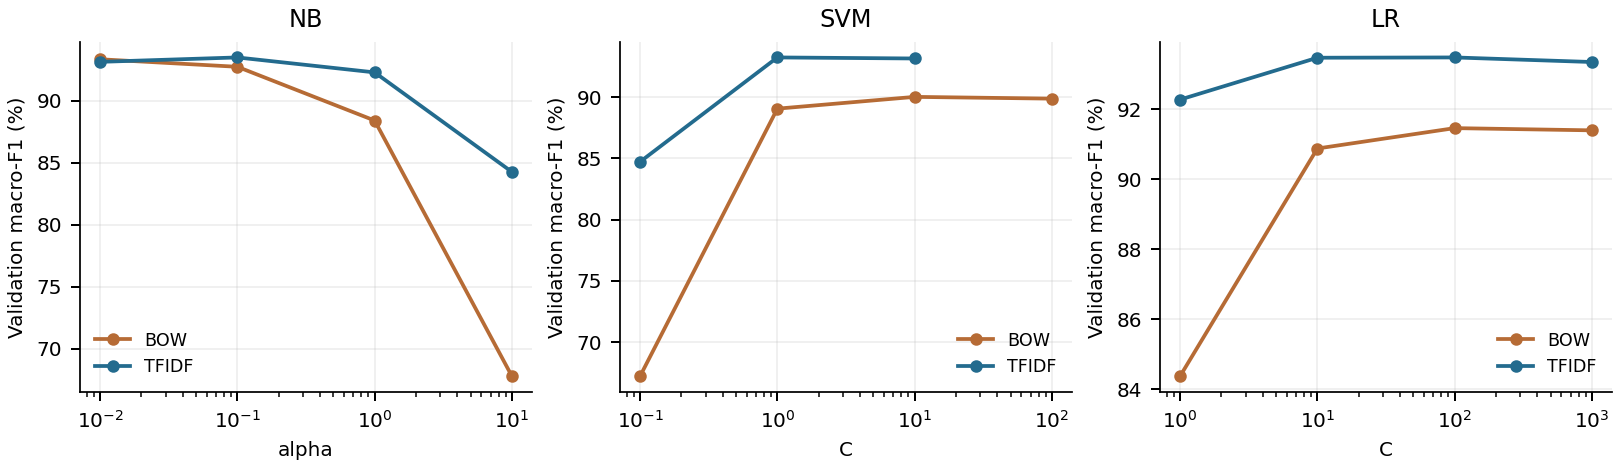

In [4]:
columns = ['representation', 'model', 'params', 'train_macro_f1', 'macro_f1', 'accuracy', 'fit_seconds', 'warning']
comparison = runs[(runs.seed == config['seed']) & (runs.stage == 'comparison')]
display(comparison[columns].sort_values(['representation', 'model', 'macro_f1'], ascending=[True, True, False]).reset_index(drop=True))
display(Image(filename=str(ROOT / 'report/figures/parameter_search.png')))

## 4. 模型和文本表示

每个“模型 × 表示”先在规定范围内取验证 Macro-F1 最高的配置。表中的时间只包含分类器拟合，不包含向量化；Word2Vec 的构造时间单独列出。验证集已经参与参数选择，所以这些数字不是未知测试集成绩。

In [5]:
display(result['main'][['representation', 'model', 'params', 'accuracy', 'macro_f1', 'fit_seconds', 'n_features']].reset_index(drop=True))
w2v = runs[(runs.seed == config['seed']) & (runs.representation == 'word2vec')]
display(w2v[['params', 'accuracy', 'macro_f1', 'feature_seconds', 'fit_seconds']].reset_index(drop=True))

,representation,model,params,accuracy,macro_f1,fit_seconds,n_features
0,bow,LR,"{""C"": 100.0}",0.9144,0.9146,8.0231,15000
1,tfidf,LR,"{""C"": 100.0}",0.9348,0.9348,5.0895,15000
2,bow,MLP,"{""alpha"": 0.0001, ""hidden"": [64]}",0.9395,0.9395,80.5101,15000
3,tfidf,MLP,"{""alpha"": 0.0001, ""hidden"": [64]}",0.9423,0.9422,99.1350,15000
4,bow,NB,"{""alpha"": 0.01}",0.9334,0.9336,0.0101,15000
5,tfidf,NB,"{""alpha"": 0.1}",0.9348,0.9351,0.0079,15000
6,bow,SVM,"{""C"": 10.0}",0.9001,0.9001,14.8603,15000
7,tfidf,SVM,"{""C"": 1.0}",0.9321,0.9323,18.5777,15000


,params,accuracy,macro_f1,feature_seconds,fit_seconds
0,"{""C"": 1.0}",0.8526,0.8520,212.7568,0.3647
1,"{""C"": 10.0}",0.8750,0.8745,212.7568,0.8161
2,"{""C"": 100.0}",0.8736,0.8735,212.7568,1.8541


平均 Word2Vec 只用当前训练部分从头学习，再配合 LR 搜索 `C`。这个设置与预训练词向量或 BERT 不同，因此这里只评价简单平均词向量，不能把结果推广到所有稠密表示。

## 5. 标题与正文

接着固定首轮 TF-IDF 中表现最好的分类器和参数，比较仅正文、标题正文直接拼接，以及分别向量化后再拼接。标题权重取 0.5、1 和 2。分开表示会同时改变词表、IDF 统计范围和特征维数，所以把它看作一整套结构处理。

,view,title_weight,params,n_features,train_macro_f1,macro_f1,accuracy,fit_seconds
0,joined,1.0,"{""alpha"": 0.0001, ""hidden"": [64]}",15000,0.9998,0.9422,0.9423,99.1350
1,body,1.0,"{""alpha"": 0.0001, ""hidden"": [64]}",15000,0.9981,0.9253,0.9253,118.8777
2,separate,0.5,"{""alpha"": 0.0001, ""hidden"": [64]}",17500,0.9998,0.9483,0.9484,119.2717
3,separate,1.0,"{""alpha"": 0.0001, ""hidden"": [64]}",17500,0.9998,0.9471,0.9470,119.3977
4,separate,2.0,"{""alpha"": 0.0001, ""hidden"": [64]}",17500,0.9998,0.9322,0.9321,119.6418


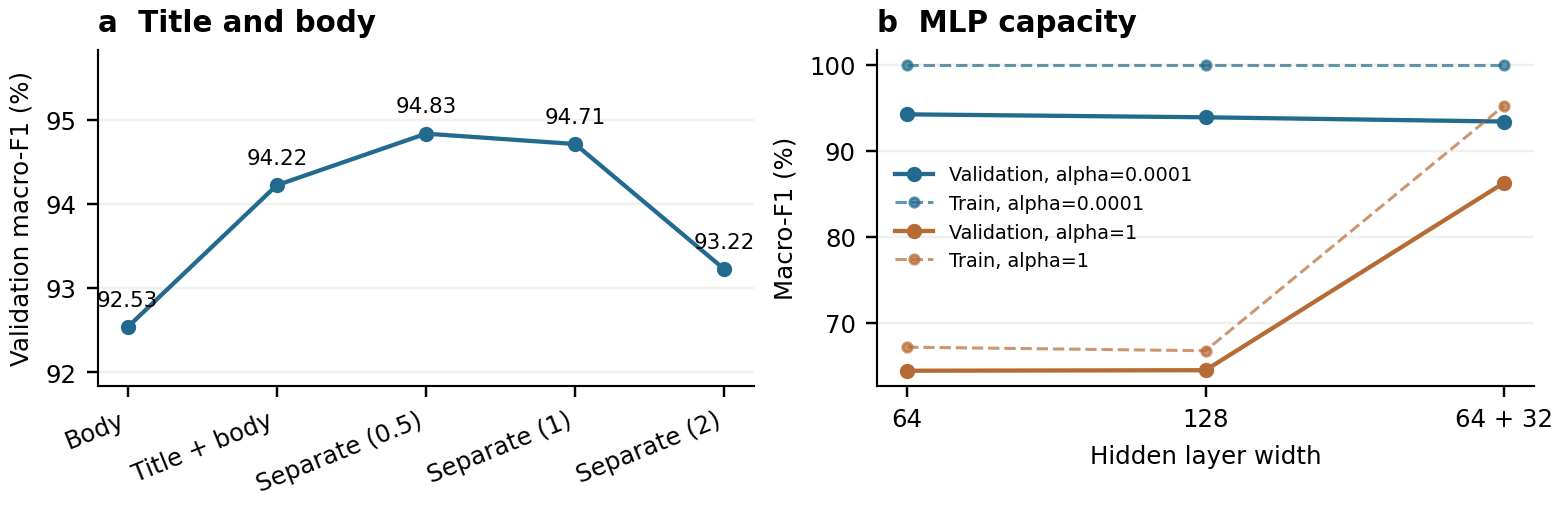

In [6]:
display(result['structure'][['view', 'title_weight', 'params', 'n_features', 'train_macro_f1', 'macro_f1', 'accuracy', 'fit_seconds']].reset_index(drop=True))
display(Image(filename=str(ROOT / 'report/figures/comparisons.png')))

## 6. MLP 容量与正则化

容量实验比较单层 64、单层 128 和双层 64＋32，并分别设置较弱和较强的 L2 正则化。双层结构同时改变层数和连接方式，不能把差异完全解释为“深度”的作用。训练分数、验证分数、迭代次数和收敛警告需要一起看。

,params,parameter_count,iterations,train_macro_f1,macro_f1,fit_seconds,warning
0,"{""alpha"": 0.0001, ""hidden"": [64]}",960714,101,0.9998,0.9422,99.1350,
1,"{""alpha"": 0.01, ""hidden"": [64]}",960714,209,0.9998,0.9334,220.0036,
2,"{""alpha"": 1.0, ""hidden"": [64]}",960714,209,0.6714,0.6440,224.6528,
3,"{""alpha"": 0.0001, ""hidden"": [128]}",1921418,99,0.9998,0.9388,173.7114,
4,"{""alpha"": 1.0, ""hidden"": [128]}",1921418,157,0.6673,0.6446,270.9310,
5,"{""alpha"": 0.0001, ""hidden"": [64, 32]}",962474,78,0.9998,0.9338,66.9033,
6,"{""alpha"": 1.0, ""hidden"": [64, 32]}",962474,140,0.9520,0.8624,130.9871,


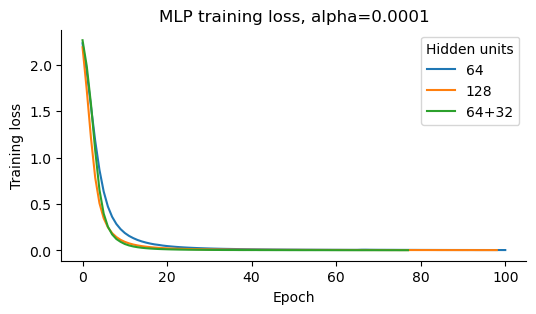

In [7]:
display(result['capacity'][['params', 'parameter_count', 'iterations', 'train_macro_f1', 'macro_f1', 'fit_seconds', 'warning']].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(6, 3))
for record in records:
    spec = record['spec']
    if (record['seed'] == config['seed'] and spec['model'] == 'MLP'
            and spec['representation'] == 'tfidf' and spec['view'] == 'joined'
            and spec['params']['alpha'] == 0.0001):
        ax.plot(record['loss_curve'], label='+'.join(map(str, spec['params']['hidden'])))
ax.set(xlabel='Epoch', ylabel='Training loss', title='MLP training loss, alpha=0.0001')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(title='Hidden units')
plt.show()

## 7. 换一个划分再看

主划分上选好配置后，再用种子 88 复核。两次划分有样本重叠，参数也来自种子 66，因此这里只观察结果是否对划分特别敏感，不计算置信区间。

In [8]:
focus = runs[(runs.seed.isin([66, 88])) & (runs.model == 'MLP')
             & (runs.representation == 'tfidf') & (runs.params.str.contains('0.0001'))
             & ((runs['view'] == 'joined') | ((runs['view'] == 'separate') & (runs.title_weight == 0.5)))]
display(focus[['seed', 'view', 'title_weight', 'macro_f1', 'accuracy', 'fit_seconds']]
        .sort_values(['view', 'title_weight', 'seed']).reset_index(drop=True))

,seed,view,title_weight,macro_f1,accuracy,fit_seconds
0,66,joined,1.0,0.9422,0.9423,99.1350
1,66,joined,1.0,0.9388,0.9389,173.7114
2,66,joined,1.0,0.9338,0.9341,66.9033
3,88,joined,1.0,0.9357,0.9355,100.0827
4,66,separate,0.5,0.9483,0.9484,119.2717
5,88,separate,0.5,0.9344,0.9341,113.5714


## 8. 分类表现和错误样本

课程材料没有给出数字标签与新闻组名称的映射，因此保留 0–9 的原始标签。分类报告用于寻找表现偏低的类别，混淆矩阵的行是真实标签，列是预测标签。

In [9]:
selected_id = json.loads((ROOT / 'results/selection.json').read_text(encoding='utf-8'))['selected_run_id']
selected = next(r for r in records if r['run_id'] == selected_id)
report = pd.DataFrame({k: v for k, v in selected['classification_report'].items() if isinstance(v, dict)}).T
display(report)
display(pd.DataFrame(selected['confusion_matrix'], index=range(10), columns=range(10)))
display(pd.read_csv(ROOT / 'results/error_examples.csv').head(8))
display(pd.read_csv(ROOT / 'results/title_changed_examples.csv').head(8))

,precision,recall,f1-score,support
0,0.9054,0.9178,0.9116,146.0
1,0.8973,0.8912,0.8942,147.0
2,0.8811,0.8571,0.8690,147.0
3,0.9536,0.9730,0.9632,148.0
4,0.9860,0.9463,0.9658,149.0
5,0.9800,0.9866,0.9833,149.0
6,1.0000,0.9732,0.9864,149.0
7,0.9177,0.9797,0.9477,148.0
8,0.9795,0.9662,0.9728,148.0
9,0.9859,0.9929,0.9894,141.0


,0,1,2,3,4,5,6,7,8,9
0,134,3,6,0,1,1,0,1,0,0
1,6,131,9,0,0,0,0,1,0,0
2,3,9,126,1,0,0,0,7,1,0
3,0,1,0,144,1,0,0,1,1,0
4,2,0,0,4,141,0,0,1,0,1
5,0,0,0,2,0,147,0,0,0,0
6,0,1,0,0,0,1,145,2,0,0
7,1,0,2,0,0,0,0,145,0,0
8,2,1,0,0,0,1,0,0,143,1
9,0,0,0,0,0,0,0,0,1,140


,row_id,target,prediction,title,body_excerpt
0,1606,4,3,stolen CBR900RR,Stolen from Pasadena between 4:30 and 6:30 pm on 4/15. Blue and white Honda ...
1,4799,4,7,xs1100 timing,Could some kind soul tell me the advance timing/revs for a 1981 xs1100 speci...
2,1252,3,1,Squeekin' Windows,arlen.r.martin (arm1@cbnewsm.cb.att.com) wrote: : Consumer Reports once wrot...
3,2656,1,7,VideoBlaster & PC SPEAKER,Software that comes together with the VideoBlaster is designed to work toget...
4,2769,0,2,ACCESS.bus (Re: ACCESS.bus Software Creator's Contest),Intro to ACCESS.bus (RE: the ACCESS.bus Software Creator's Contest Announcem...
5,4570,7,0,Looking for a good Spice book,In article <canright.734829385@convex.com> canright@convex.com (Robert Canri...
6,4021,2,1,Scan Rate vs. Font Size,This past winter I found myself spending a ridiculous amout of time in front...
7,7125,2,8,trakker backup,To those who own CMS's Trakkers...please email me with your thoughts on your...


,row_id,target,joined_prediction,body_prediction,title,body_excerpt
0,1606,4,3,4,stolen CBR900RR,Stolen from Pasadena between 4:30 and 6:30 pm on 4/15. Blue and white Honda ...
1,1338,3,3,5,Questions about insurance companies (esp. Geico),Bob: Excellent! To the point and correct! Spread the word.
2,6354,7,7,0,Laser vs Bubblejet?,In article <735446880snx@black.demon.co.uk> tchannon@black.demon.co.uk write...
3,4799,4,7,3,xs1100 timing,Could some kind soul tell me the advance timing/revs for a 1981 xs1100 speci...
4,1062,2,2,7,Need info on PS/2 mouse port,Would someone please email me the pinout for a PS/2 6-pin mini DIN mouse por...
5,6234,2,2,1,Help: Blowing the stack,"Hi everyone, I have a question regarding my stack on my pc. I am programming..."
6,372,7,7,5,"Conductive Plastic, what happened?",If you're thinking of reactive polymers they're making ESD safe contauiners...
7,1259,0,0,1,Vesa on the Speedstar 24,"Just posting to John Cormack. I wanted to tell you that there is a ""slight"" ..."


## 9. 这次实验得到什么

经过这些尝试，主划分最后选中的方案为 `tfidf` 表示、`separate` 结构、标题权重 `0.5`，分类器参数为 `{'hidden': [64], 'alpha': 0.0001}`。验证 Accuracy 为 94.84%，Macro-F1 为 94.83%。

仅看主划分，标题与正文分开处理比直接拼接高 0.61 个百分点，比只保留正文高 2.30 个百分点。到了种子 88，直接拼接为 93.57%，分开处理为 93.44%，顺序发生了反转，因此不能把不足一个百分点的差距写成普遍规律。

结果还说明模型复杂度不是越高越好：更宽或更深的 MLP 需要更多计算，验证表现却可能下降。平均 Word2Vec 的表现则受到语料规模、从头训练和简单均值聚合的共同限制。结论只适用于当前数据、预处理和搜索范围。

## 10. 最终预测

方案锁定后，在全部 7,368 条有标签数据上重新拟合特征和模型，再按原顺序预测无标签测试集。`prediction.csv` 只有一列、没有表头。测试集没有标签，因此没有测试 Accuracy 或 Macro-F1。

In [10]:
final = json.loads((ROOT / 'results/final_fit.json').read_text(encoding='utf-8'))
prediction = pd.read_csv(ROOT / 'output/prediction.csv', header=None)
display(final)
print('prediction.csv 行数：', len(prediction))
print('标签集合：', sorted(prediction.iloc[:, 0].unique().tolist()))
assert len(prediction) == final['test_rows']

{'selected_spec': {'model': 'MLP',
  'params': {'hidden': [64], 'alpha': 0.0001},
  'representation': 'tfidf',
  'view': 'separate',
  'title_weight': 0.5},
 'fit_seconds': 110.09580600005575,
 'train_rows': 7368,
 'test_rows': 2457,
 'test_sha256': '4882c04b008c055f351f1c9b25c45d601a454077af37e79375601f2465b41615',
 'prediction_sha256': '216a0a2ca70c2264d44e284ba95b3771aa69bd4e60e5ed2b4b3ad07cd137f62f',
 'label_counts': {'0': 258,
  '1': 240,
  '2': 240,
  '3': 241,
  '4': 249,
  '5': 251,
  '6': 249,
  '7': 250,
  '8': 244,
  '9': 235}}

prediction.csv 行数： 2457
标签集合： [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 参考资料

- [scikit-learn：文本特征提取](https://scikit-learn.org/1.2/modules/feature_extraction.html#text-feature-extraction)
- [scikit-learn：朴素贝叶斯](https://scikit-learn.org/1.2/modules/naive_bayes.html)
- [scikit-learn：支持向量机](https://scikit-learn.org/1.2/modules/svm.html)
- [scikit-learn：多层感知机](https://scikit-learn.org/1.2/modules/neural_networks_supervised.html)
- [Gensim：Word2Vec](https://radimrehurek.com/gensim/models/word2vec.html)
